<a href="https://colab.research.google.com/github/claudio-iturra/doctoral-thesis/blob/main/004-make_rotary.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import glob
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import savgol_filter

In [ ]:
cd /content/drive/MyDrive/dropbox_server/research_database/remote/mercator/chile/2024

/content/drive/MyDrive/dropbox_server/research_database/remote/mercator/chile/2024


In [ ]:
ls -l

total 8415207
-rw------- 1 root root  696822657 Sep 27 13:27 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758979651273.nc
-rw------- 1 root root  720627969 Sep 27 13:33 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758979978136.nc
-rw------- 1 root root  720627969 Sep 27 13:36 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980186048.nc
-rw------- 1 root root  732530625 Sep 27 13:42 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980558209.nc
-rw------- 1 root root  714676641 Sep 27 13:45 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980749764.nc
-rw------- 1 root root  714676641 Sep 27 13:51 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758981065903.nc
-rw------- 1 root root 4299862082 Oct 22 01:24 data.nc
-rw------- 1 root root    1148420 Oct 23 15:42 make_rotary_area.ipynb
-rw------- 1 root root     944813 Oct 23 02:15 make_rotary_filter.ipynb
-rw------- 1 root root    9697877 Oct 29 14:20 make_rotary.ipynb
-rw------- 1 root root    5552368 Oct 28 23:38 rotary_data.pkl
-rw------- 1 root root         48 Oct 23 15

In [ ]:
nc_files = glob.glob("cmems_mod_glo_phy_anfc_0.083deg_PT1H-m*.nc")

In [ ]:
nc_files

['cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758979651273.nc',
 'cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758979978136.nc',
 'cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980186048.nc',
 'cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980558209.nc',
 'cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980749764.nc',
 'cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758981065903.nc']

In [ ]:
# Concatenate along time dimension
ds = xr.open_mfdataset(nc_files, combine='by_coords')

In [ ]:
#ds.to_netcdf("data.nc")

In [ ]:
ds

<xarray.Dataset> Size: 4GB
Dimensions:    (time: 8670, depth: 1, latitude: 504, longitude: 123)
Coordinates:
  * time       (time) datetime64[ns] 69kB 2024-01-01T23:00:00 ... 2024-12-31T...
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 2kB -57.67 -57.58 -57.5 ... -15.83 -15.75
  * longitude  (longitude) float32 492B -78.0 -77.92 -77.83 ... -67.92 -67.83
Data variables:
    uo         (time, depth, latitude, longitude) float32 2GB dask.array<chunksize=(1405, 1, 504, 123), meta=np.ndarray>
    vo         (time, depth, latitude, longitude) float32 2GB dask.array<chunksize=(1405, 1, 504, 123), meta=np.ndarray>
Attributes:
    Conventions:       CF-1.11
    title:             hourly mean fields from Global Ocean Physics Analysis ...
    institution:       Mercator Ocean International
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MOI GLO12
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           https://marine.copernicus.eu/contact
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_ANALYSISFORECAST_PHY_001_024
    subset:datasetId:  cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_202406
    subset:date:       2025-09-27T13:27:31.273Z

In [ ]:
!pip install cartopy
import cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 66.4 MB/s eta 0:00:00


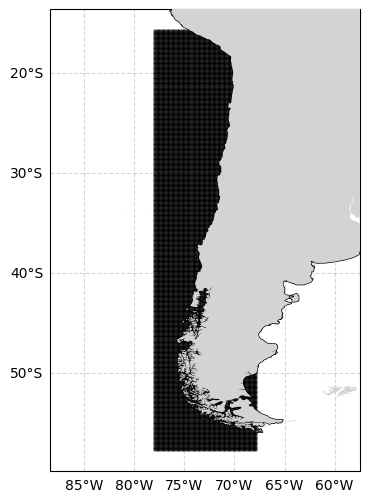

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

lat_min, lat_max = -37.5, -35.5
lon_min, lon_max = -74, -72.3

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(4,6))

ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution="10m", color="black", linewidth=1)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=5)
gl = ax.gridlines(draw_labels=True, linestyle="--", alpha=0.5)
gl.top_labels = False
gl.right_labels = False


[lon,lat] = np.meshgrid(ds['longitude'],ds['latitude'])
plt.plot(lon,lat, color = 'k', linestyle = 'none', marker = '.', markersize = 0.5)
plt.axis('equal')
plt.grid()

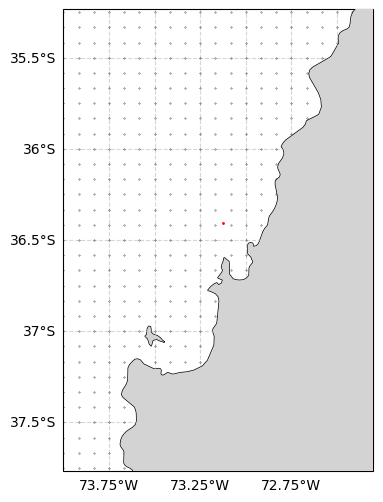

In [ ]:
lat_min, lat_max = -37.5, -35.5
lon_min, lon_max = -74, -72.3

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(4,6))

ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution="10m", color="black", linewidth=1)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=5)
gl = ax.gridlines(draw_labels=True, linestyle="--", alpha=0.5)
gl.top_labels = False
gl.right_labels = False


[lon,lat] = np.meshgrid(ds['longitude'],ds['latitude'])
plt.plot(lon,lat, color = 'k', linestyle = 'none', marker = '.', markersize = 0.5)
plt.plot(-73.1224,-36.4075, marker='o', linestyle='none', color= 'red', markersize=1);
plt.axis('equal')
plt.ylim([-37.5, -35.5])
plt.xlim([-74, -72.3])
plt.grid()

In [ ]:
l1 = ds.sel(latitude=-36.4075, longitude=-73.1224, method='nearest')

((-0.4, 0.4),
 None,
 Text(0, 0.5, 'm/s'))

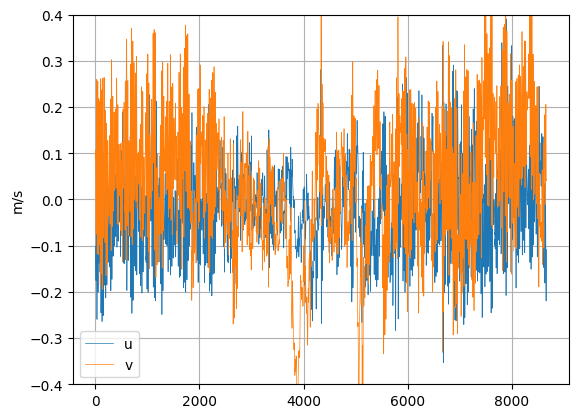

In [ ]:
plt.plot(l1['uo'], linewidth=0.5, label = 'u')
plt.plot(l1['vo'], linewidth=0.5, label = 'v')
plt.ylim([-0.4,0.4]), plt.legend(), plt.grid(), plt.ylabel('m/s')

In [ ]:
!pip install multitaper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 21.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for multitaper: filename=multitaper-1.2.0-py3-none-any.whl size=1794320 sha256=504e3ffd86b0067d12a390a461e384276fa6aa09026c5df39ad97aa8493dcdfe
  Stored in directory: /root/.cache/pip/wheels/21/bd/ea/6e731f3f461db422b987a588f275db7724211675bc29c08ca7
Successfully built multitaper


In [ ]:
from multitaper import MTSpec

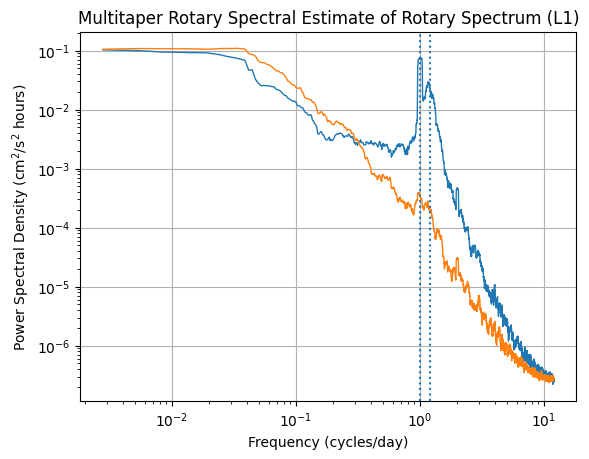

In [ ]:
dt = (1)/24
cv = l1['uo'].values.flatten() +1j*l1['vo'].values.flatten()
P = 16
spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
S = np.ravel(spec.spec)
f = np.ravel(spec.freq)
plt.loglog( f[f>0],S[f>0], linewidth = 1)#plot positive side
plt.loglog(-f[f<0],S[f<0], linewidth = 1)#plot negative side
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.xlabel('Frequency (cycles/day)')
plt.ylabel('Power Spectral Density (cm$^2$/s$^2$ hours)')
plt.title('Multitaper Rotary Spectral Estimate of Rotary Spectrum (L1)')
plt.grid()
del cv, P, spec, S, f, dt

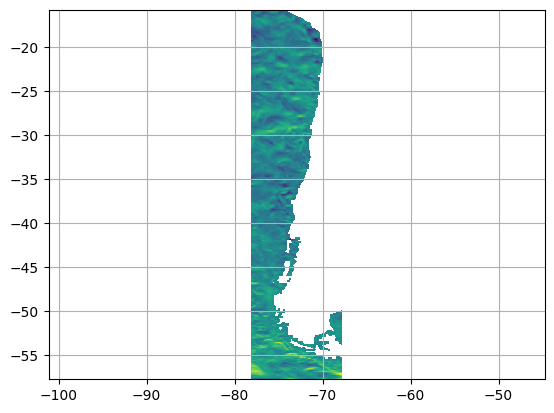

In [ ]:
plt.pcolor(ds[ 'longitude'],ds['latitude'],ds[ 'uo'][0,0,:,:])
plt.axis('equal')
plt.grid()

(-74.0, -72.3)

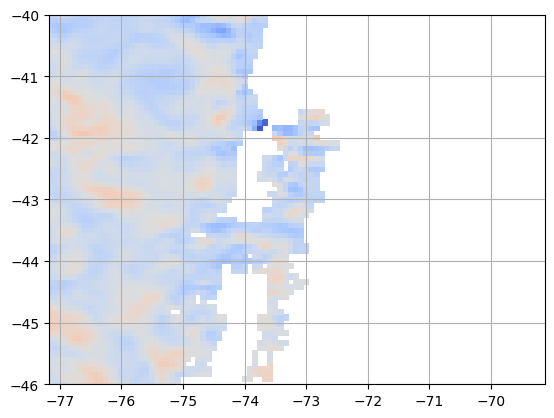

In [ ]:
plt.pcolor(ds[ 'longitude'],ds['latitude'],ds[ 'uo'][0,0,:,:], cmap = 'coolwarm')
plt.axis('equal')
plt.grid()
plt.ylim([-46, -40])
plt.xlim([-74, -72.3])

In [ ]:
lonz = [
-71.177653791328197,
-70.791924990329804,
-70.685150518884299,
-70.737401113210694,
-70.9597164385345,
-71.134418789530798,
-71.514820345619498,
-71.971434262285101,
-72.113558548046896,
-72.076116200242296,
-72.094079325261404,
-72.348634110154606,
-72.859354620603199,
-73.404510581256005,
-73.826756878327899,
-73.962365615990194,
-74.077496110334096,
-74.067415737309602,
-73.989222481057297,
-74.090188277440802,
-74.236516458766502,
-74.365538034134602,
-74.670308160475301,
-74.674460040772004,
-74.6720783327915,
-74.779107555190507,
-74.964076880347903,
-75.080032449979299,
-75.260124426034196,
-75.304209779955102,
-75.159739129974994,
-75.890951147045001,
-76.057530345494698,
-75.924540513162498,
-75.606997083033207,
-75.129321274508001,
-74.207456022141599,
-73.059666946411099,
-71.353655237317696,
-68.986822172941103
]


In [ ]:
latz = [
-18.810678167335102,
-19.891140092917599,
-20.975208486143401,
-22.2331324804139,
-24.215608447367298,
-25.937220691265299,
-27.717197931745201,
-29.526017427591501,
-30.960447659889802,
-31.688467635049001,
-32.759009446956497,
-33.7288164568509,
-35.007158848764099,
-36.198161756924499,
-36.818762763460903,
-37.097436960319598,
-37.631470148013797,
-38.334513088872697,
-39.040093468735698,
-39.655598758098201,
-40.229036360218998,
-40.8753151329947,
-41.8582056622054,
-42.373719436018199,
-42.834007874410801,
-43.387049719424397,
-44.158862284763799,
-44.575126109814597,
-45.491438798487998,
-45.860758430342798,
-47.2857242863887,
-48.432045946779198,
-49.549436425112702,
-50.626314630577298,
-52.034201241531697,
-52.815753463738197,
-53.979981715661502,
-54.771468418395898,
-55.395828094971897,
-56.464299846520397
]

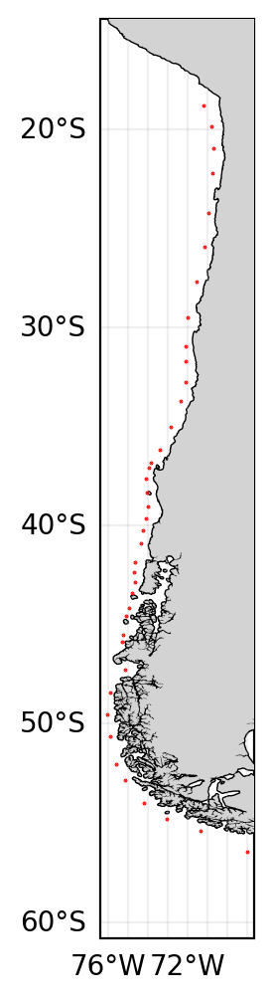

In [ ]:
from matplotlib import pyplot
pyplot.rcParams['figure.dpi'] = 200

lat_min, lat_max = -37.5, -35.5
lon_min, lon_max = -74, -72.3

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(1,6))

ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution="10m", color="black", linewidth=1)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=5)
gl = ax.gridlines(draw_labels=True, linestyle="-", alpha=0.2)
gl.top_labels = False
gl.right_labels = False

plt.plot(lonz,latz, color = 'r', linestyle = 'none', marker = '.', markersize = 0.8)
plt.axis('equal')
plt.grid()

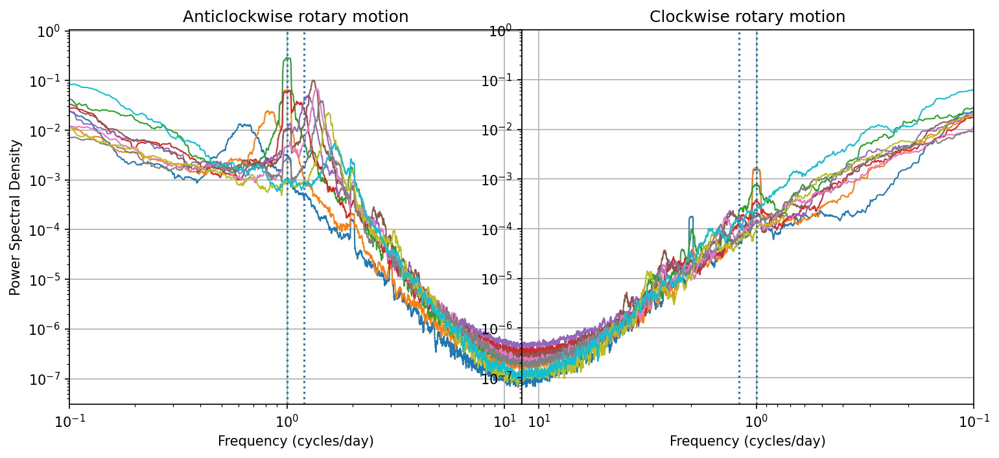

In [ ]:
pyplot.rcParams['figure.dpi'] = 150

plt.figure(figsize=(12,5))
for i in range(0,len(lonz),4):
  l1 = ds.sel(latitude=latz[i], longitude=lonz[i], method='nearest')
  dt = (1)/24
  cv = l1['uo'].values.flatten() +1j*l1['vo'].values.flatten()
  P = 16
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  plt.subplot(1,2,1)
  plt.loglog( f[f>0],S[f>0], linewidth = 1)#plot positive side
  plt.subplot(1,2,2)
  plt.loglog(-f[f<0],S[f<0], linewidth = 1)#plot negative side
  del cv, P, spec, S, f, dt

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.grid()
plt.xlim([0.1,12])

plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.grid()
plt.xlim([0.1,12])
plt.gca().invert_xaxis()

plt.subplots_adjust(wspace=0, hspace=0)

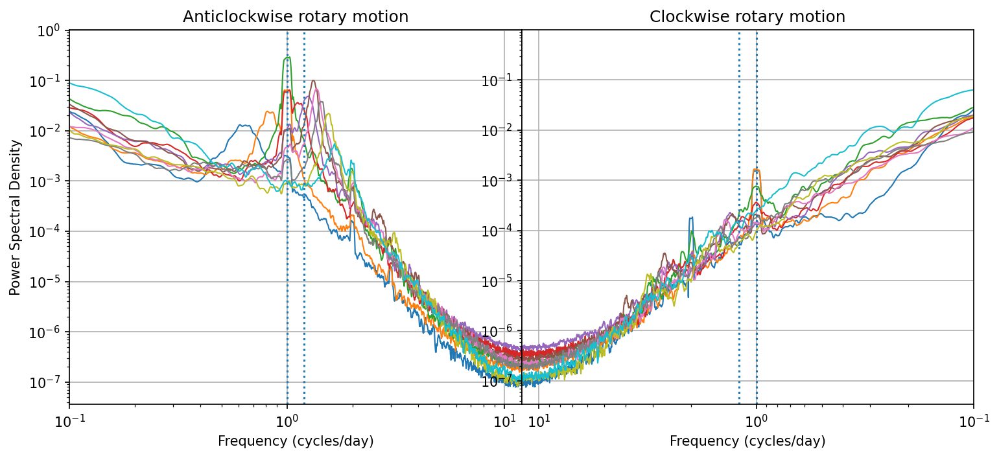

In [ ]:
pyplot.rcParams['figure.dpi'] = 150

plt.figure(figsize=(12,5))
for i in range(0,len(lonz),4):
  l1 = ds.sel(latitude=latz[i], longitude=lonz[i], method='nearest')
  dt = (1)/24
  cv = l1['uo'].values.flatten() +1j*l1['vo'].values.flatten()
  P = 16
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  plt.subplot(1,2,1)
  plt.loglog( f[f>0],savgol_filter(S[f>0],15,2), linewidth = 1)#plot positive side
  plt.subplot(1,2,2)
  plt.loglog(-f[f<0],savgol_filter(S[f<0],15,2), linewidth = 1)#plot negative side
  del cv, P, spec, S, f, dt

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.grid()
plt.xlim([0.1,12])

plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.grid()
plt.xlim([0.1,12])
plt.gca().invert_xaxis()

plt.subplots_adjust(wspace=0, hspace=0)

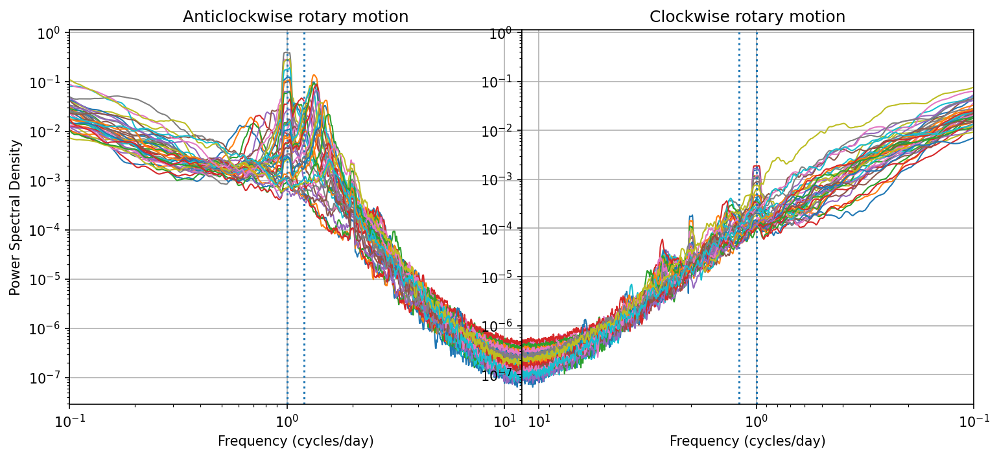

In [ ]:
plt.figure(figsize=(12,5))
for i in range(0,len(lonz)):
  l1 = ds.sel(latitude=latz[i], longitude=lonz[i], method='nearest')
  dt = (1)/24
  cv = l1['uo'].values.flatten() +1j*l1['vo'].values.flatten()
  P = 16
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  plt.subplot(1,2,1)
  plt.loglog( f[f>0],savgol_filter(S[f>0],15,2), linewidth = 1)#plot positive side
  plt.subplot(1,2,2)
  plt.loglog(-f[f<0],savgol_filter(S[f<0],15,2), linewidth = 1)#plot negative side
  del cv, P, spec, S, f, dt

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.grid()
plt.xlim([0.1,12])

plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.grid()
plt.xlim([0.1,12])
plt.gca().invert_xaxis()

plt.subplots_adjust(wspace=0, hspace=0)

In [ ]:
dens = []
freq = []


In [ ]:
for i in range(0,len(lonz)):
  l1 = ds.sel(latitude=latz[i], longitude=lonz[i], method='nearest')
  dt = (1)/24
  cv = l1['uo'].values.flatten()*(2**i) +1j*l1['vo'].values.flatten()*(2**i)
  P = 16
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  dens.append(S)
  freq.append(f)
  del cv, P, spec, S, f, dt


In [ ]:
import pickle

with open('rotary_data.pkl', 'wb') as f:
    pickle.dump((dens, freq), f)

In [ ]:
ls -l

total 8415207
-rw------- 1 root root  696822657 Sep 27 13:27 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758979651273.nc
-rw------- 1 root root  720627969 Sep 27 13:33 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758979978136.nc
-rw------- 1 root root  720627969 Sep 27 13:36 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980186048.nc
-rw------- 1 root root  732530625 Sep 27 13:42 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980558209.nc
-rw------- 1 root root  714676641 Sep 27 13:45 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758980749764.nc
-rw------- 1 root root  714676641 Sep 27 13:51 cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_1758981065903.nc
-rw------- 1 root root 4299862082 Oct 22 01:24 data.nc
-rw------- 1 root root    1148420 Oct 23 15:42 make_rotary_area.ipynb
-rw------- 1 root root     944813 Oct 23 02:15 make_rotary_filter.ipynb
-rw------- 1 root root    9698534 Oct 29 16:18 make_rotary.ipynb
-rw------- 1 root root    5552368 Oct 29 16:19 rotary_data.pkl
-rw------- 1 root root         48 Oct 23 15

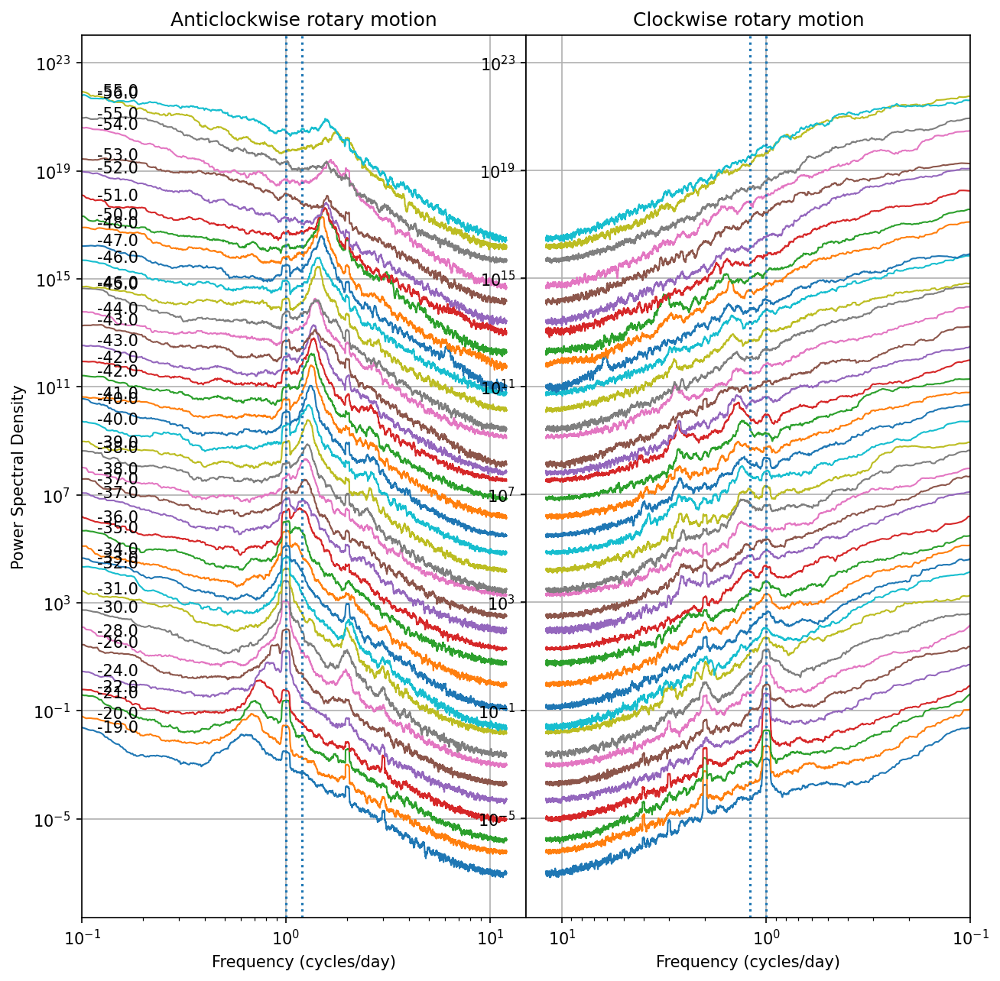

In [ ]:
plt.figure(figsize=(10,10))
for i in range(0,len(lonz)):
  l1 = ds.sel(latitude=latz[i], longitude=lonz[i], method='nearest')
  dt = (1)/24
  cv = l1['uo'].values.flatten()*(2**i) +1j*l1['vo'].values.flatten()*(2**i)
  P = 16
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  plt.subplot(1,2,1)
  plt.loglog( f[f>0],S[f>0], linewidth = 1)#plot positive side
  plt.text(f[f>0][42],S[f>0][42],np.round(l1['latitude'].values))
  plt.subplot(1,2,2)
  plt.loglog(-f[f<0],S[f<0], linewidth = 1)#plot negative side
  del cv, P, spec, S, f, dt

plt.subplot(1,2,1)
plt.xlim([0.1,15])
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.grid()

plt.subplot(1,2,2)
plt.xlim([0.1,15])
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.grid()
plt.gca().invert_xaxis()

plt.subplots_adjust(wspace=0, hspace=0)

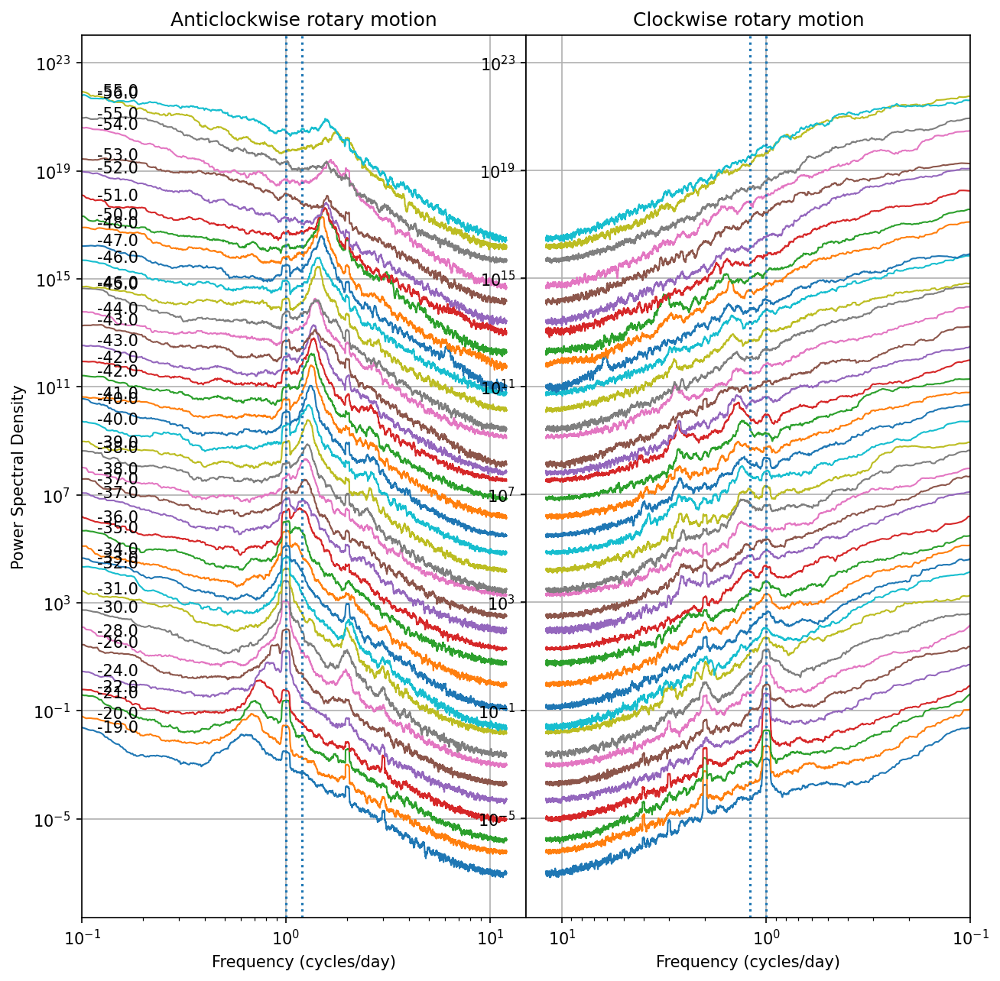

In [ ]:
plt.figure(figsize=(10,10))
for i in range(0,len(lonz)):
  l1 = ds.sel(latitude=latz[i], longitude=lonz[i], method='nearest')
  dt = (1)/24
  cv = l1['uo'].values.flatten()*(2**i) +1j*l1['vo'].values.flatten()*(2**i)
  P = 16
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  plt.subplot(1,2,1)
  plt.loglog( f[f>0],S[f>0], linewidth = 1)#plot positive side
  plt.text(f[f>0][42],S[f>0][42],np.round(l1['latitude'].values))
  plt.subplot(1,2,2)
  plt.loglog(-f[f<0],S[f<0], linewidth = 1)#plot negative side
  del cv, P, spec, S, f, dt

plt.subplot(1,2,1)
plt.xlim([0.1,15])
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.grid()

plt.subplot(1,2,2)
plt.xlim([0.1,15])
plt.axvline(24/24, linestyle = ':')
plt.axvline(24/20, linestyle = ':')
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.grid()
plt.gca().invert_xaxis()

plt.subplots_adjust(wspace=0, hspace=0)

In [ ]:
import pickle

# Load them from the file
with open('rotary_data.pkl', 'rb') as f:
    densX, freqX = pickle.load(f)

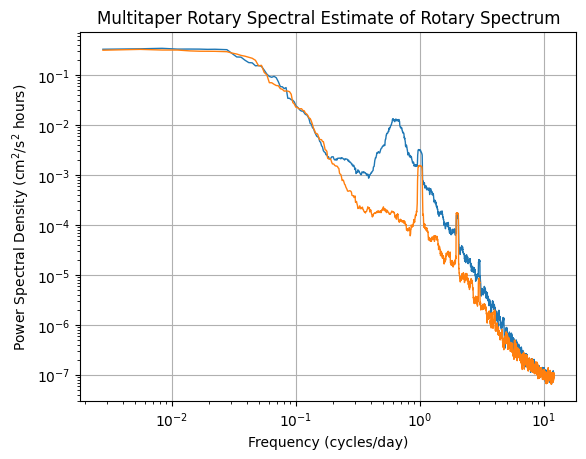

In [ ]:
pyplot.rcParams['figure.dpi'] = 100
plt.loglog( freqX[0][freqX[0]>0],densX[0][freqX[0]>0], linewidth = 1)#plot positive side
plt.loglog(-freqX[0][freqX[0]<0],densX[0][freqX[0]<0], linewidth = 1)#plot negative side
plt.xlabel('Frequency (cycles/day)')
plt.ylabel('Power Spectral Density (cm$^2$/s$^2$ hours)')
plt.title('Multitaper Rotary Spectral Estimate of Rotary Spectrum')
plt.grid()

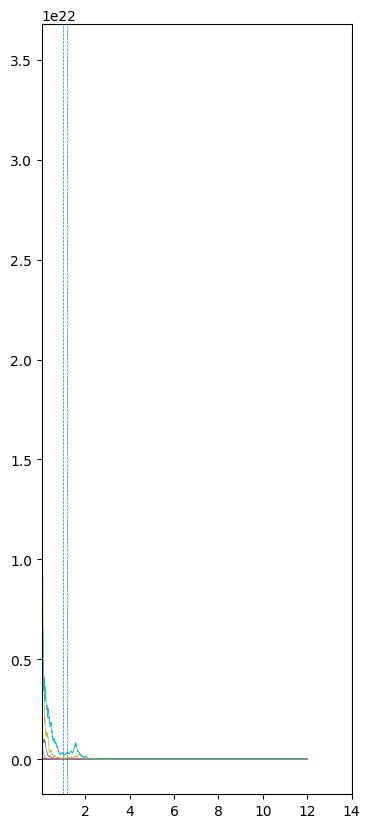

In [ ]:
plt.figure(figsize=(4,10))
for i in range(0,len(lonz)):
  plt.plot( freqX[i][freqX[i]>0],densX[i][freqX[i]>0], linewidth = 0.5)#plot positive side
  #plt.loglog(-freqX[i][freqX[i]<0],densX[i][freqX[i]<0], linewidth = 1)#plot negative side
  plt.xlim([0.05,14])
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)

In [ ]:
import numpy as np

def inertial_period_hours(latitudes_deg):
    """
    Calculate the inertial period for an array of latitudes in hours.

    Parameters:
    -----------
    latitudes_deg : array-like
        Latitudes in degrees.

    Returns:
    --------
    T_hours : ndarray
        Inertial period in hours.
    """
    # Earth's rotation rate (rad/s)
    Omega = 7.2921e-5

    # Convert degrees to radians
    latitudes_rad = np.radians(latitudes_deg)

    # Calculate inertial frequency
    f = 2 * Omega * np.sin(latitudes_rad)

    # Calculate inertial period in seconds
    T_seconds = 2 * np.pi / f

    # Convert seconds to hours
    T_hours = T_seconds / 3600

    return T_hours

In [ ]:
inertial_freq = inertial_period_hours(latz)

Text(0, 0.5, 'Latitude')

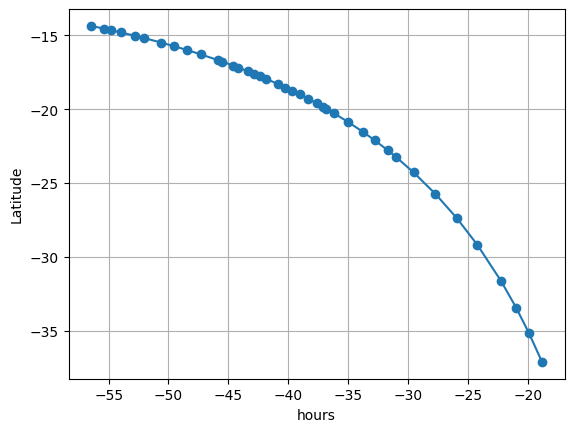

In [ ]:
plt.plot(latz,inertial_freq, marker = 'o')
plt.grid()
plt.xlabel('hours')
plt.ylabel('Latitude')

In [ ]:
nearest_value = np.full((len(lonz), 1), np.nan)
nearest_f = np.full((len(lonz), 1), np.nan)
nearest_dens = np.full((len(lonz), 1), np.nan)

for i in range(0,len(lonz)):
  z = freqX[i][freqX[i]>0]
  z1 = densX[i][freqX[i]>0]
  vector = np.array(z)
  idx = (np.abs(vector - 24/np.abs(inertial_freq[i]))).argmin()
  nearest_value[i] = idx
  nearest_f[i] = z[idx]
  nearest_dens[i] = z1[idx]
  del z, vector, idx


In [ ]:
nearest_dens_smooth = pd.Series(nearest_dens.flatten()).rolling(window=5, center=True).mean()

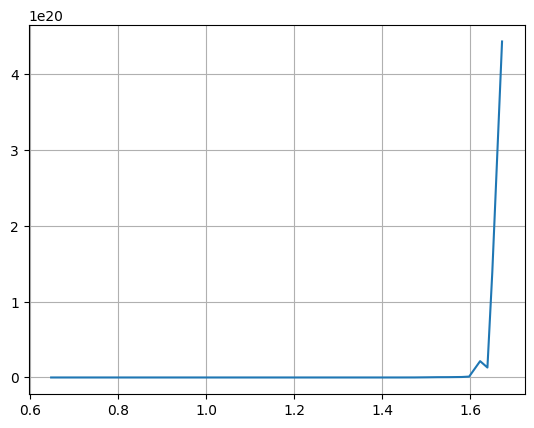

In [ ]:
plt.plot(nearest_f,nearest_dens)
plt.grid()

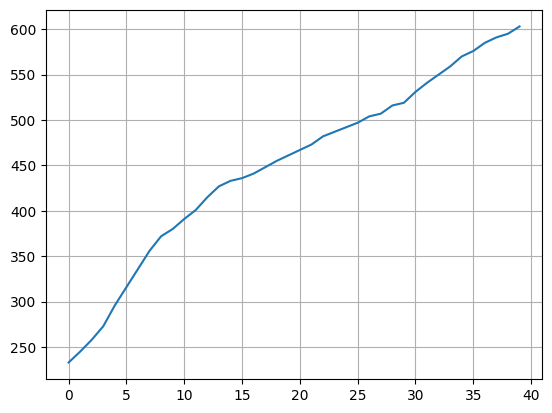

In [ ]:
plt.plot(nearest_value)
plt.grid()

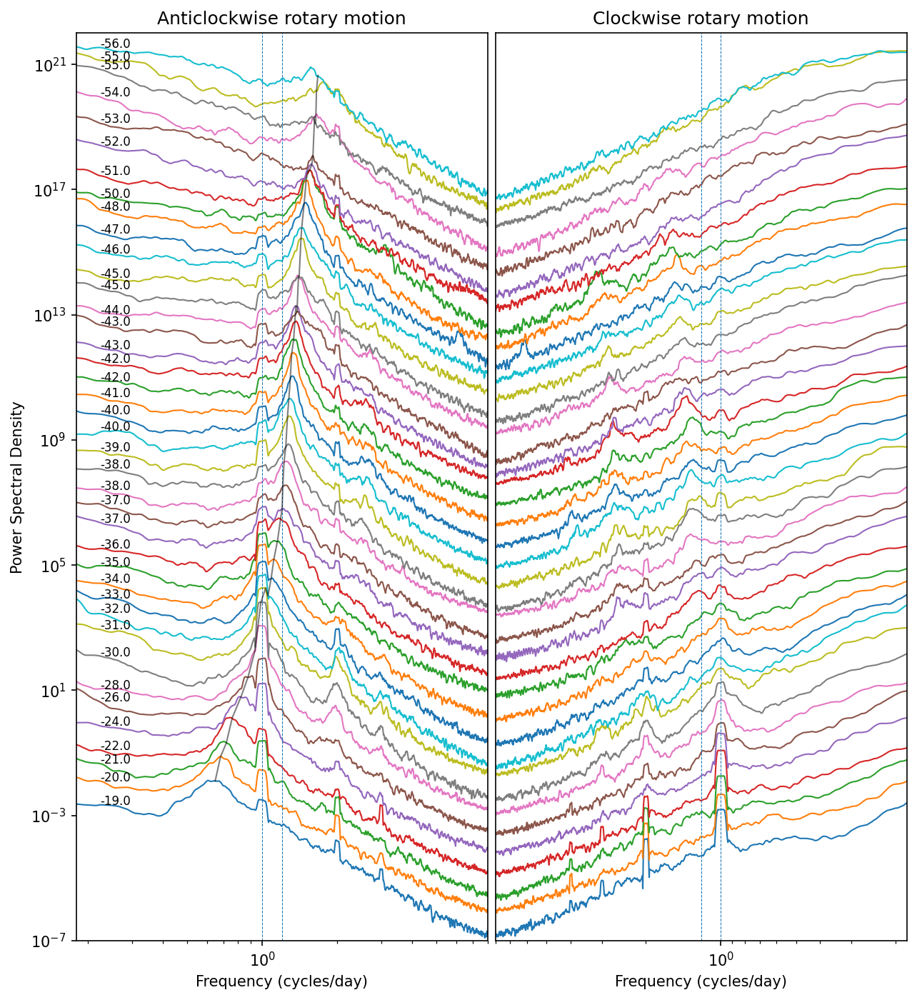

In [ ]:
pyplot.rcParams['figure.dpi'] = 150
plt.figure(figsize=(10,11))
for i in range(0,len(lonz)):
  plt.subplot(1,2,1)
  plt.loglog(freqX[i][freqX[i]>0],savgol_filter(densX[i][freqX[i]>0],15,2), linewidth = 1)#plot positive side
  plt.text(freqX[i][freqX[i]>0][80],densX[i][freqX[i]>0][80],np.round(latz[i]), fontsize = 8)
  plt.xlim([0.18,8])
  plt.subplot(1,2,2)
  plt.loglog(-freqX[i][freqX[i]<0],savgol_filter(densX[i][freqX[i]<0],15,2), linewidth = 1)#plot negative side
  plt.xlim([0.18,8])

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
#plt.plot(nearest_f.flatten(),nearest_dens.flatten(), linewidth = 1, color = 'k', linestyle='dotted')
plt.plot(nearest_f.flatten(),nearest_dens.flatten(), linewidth = 1, color = 'k', alpha = 0.5)
plt.ylim([10e-8,10e21])
plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.gca().invert_xaxis()
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.yticks([])
plt.ylim([10e-8,10e21])

plt.subplots_adjust(wspace=0.02, hspace=0)

In [ ]:
dens_in = []
freq_in = []


In [ ]:
for i in range(0,len(lonz)):
  l1 = ds.sel(latitude=latz[39-i], longitude=lonz[39-i], method='nearest')
  dt = (1)/24
  cv = l1['uo'].values.flatten()*(2**i) +1j*l1['vo'].values.flatten()*(2**i)
  P = 16
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  dens_in.append(S)
  freq_in.append(f)
  del cv, P, spec, S, f, dt

In [ ]:
nearest_value = np.full((len(lonz), 1), np.nan)
nearest_f = np.full((len(lonz), 1), np.nan)
nearest_dens = np.full((len(lonz), 1), np.nan)

for i in range(0,len(lonz)):
  z = freq_in[i][freq_in[i]>0]
  z1 = dens_in[i][freq_in[i]>0]
  vector = np.array(z)
  idx = (np.abs(vector - 24/np.abs(inertial_freq[39-i]))).argmin()
  nearest_value[i] = idx
  nearest_f[i] = z[idx]
  nearest_dens[i] = z1[idx]
  del z, vector, idx

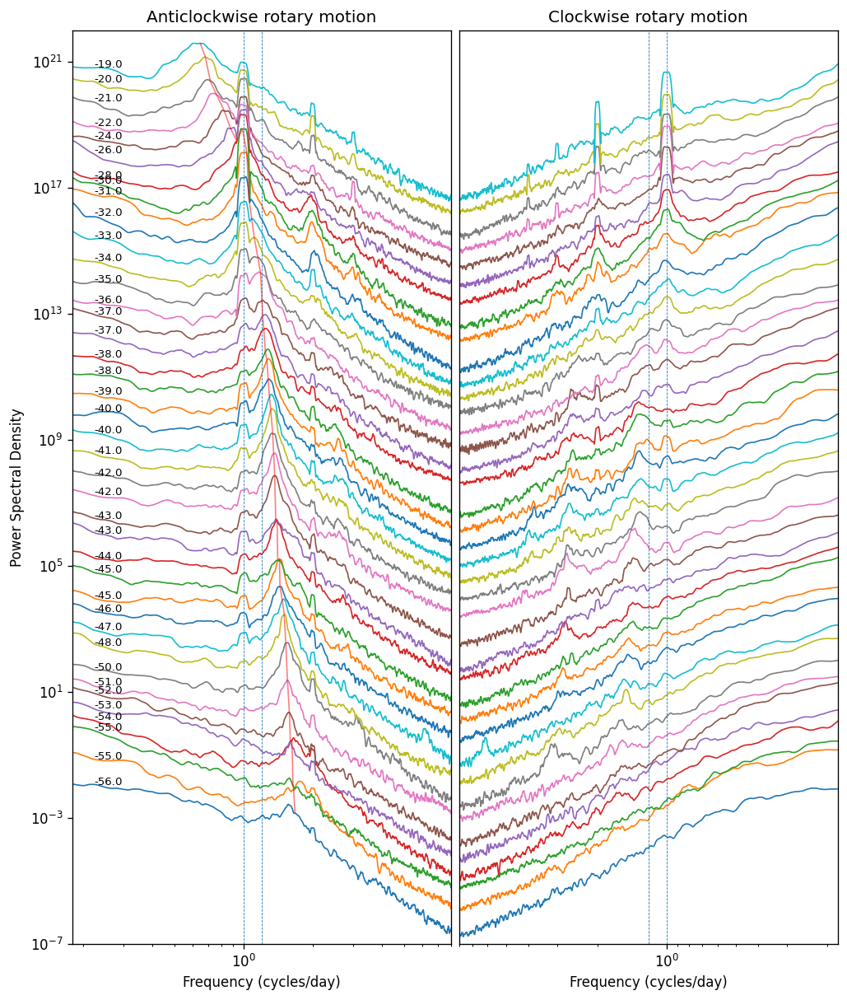

In [ ]:
pyplot.rcParams['figure.dpi'] = 120
plt.figure(figsize=(10,12))
for i in range(0,len(lonz)):
  plt.subplot(1,2,1)
  plt.loglog(freq_in[i][freq_in[i]>0],savgol_filter(dens_in[i][freq_in[i]>0],20,2), linewidth = 1)#plot positive side
  plt.text(freq_in[i][freq_in[i]>0][80],dens_in[i][freq_in[i]>0][80],np.round(latz[39-i]), fontsize = 8, color = 'k')
  plt.xlim([0.18,8])
  plt.subplot(1,2,2)
  plt.loglog(-freq_in[i][freq_in[i]<0],savgol_filter(dens_in[i][freq_in[i]<0],20,2), linewidth = 1)#plot negative side
  plt.xlim([0.18,8])

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.plot(nearest_f.flatten(),nearest_dens.flatten(), linewidth = 1, color = 'r', alpha = 0.5)
plt.ylim([10e-8,10e21])
plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.gca().invert_xaxis()
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.yticks([])
plt.ylim([10e-8,10e21])

plt.subplots_adjust(wspace=0.02, hspace=0)

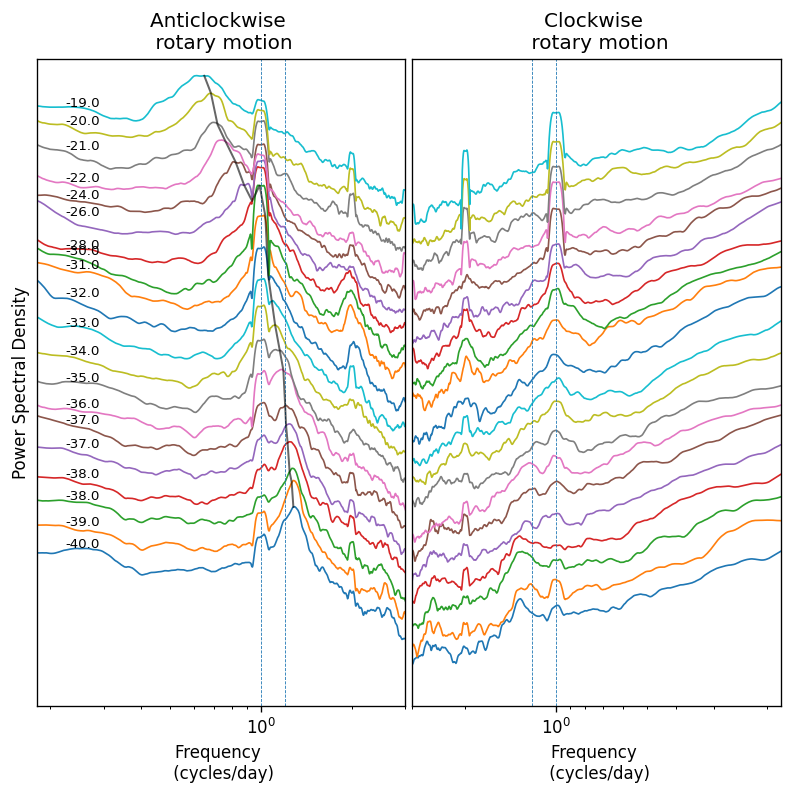

In [ ]:
pyplot.rcParams['figure.dpi'] = 120
plt.figure(figsize=(8,7))
for i in range(20,40):
  plt.subplot(1,2,1)
  plt.loglog(freq_in[i][freq_in[i]>0],savgol_filter(dens_in[i][freq_in[i]>0],20,2), linewidth = 1)#plot positive side
  plt.text(freq_in[i][freq_in[i]>0][80],dens_in[i][freq_in[i]>0][80],np.round(latz[39-i]), fontsize = 8, color = 'k')
  plt.xlim([0.18,3])
  plt.subplot(1,2,2)
  plt.loglog(-freq_in[i][freq_in[i]<0],savgol_filter(dens_in[i][freq_in[i]<0],20,2), linewidth = 1)#plot negative side
  plt.xlim([0.18,3])

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency \n (cycles/day)')
plt.title('Anticlockwise \n rotary motion')
plt.plot(nearest_f[20:40].flatten(),nearest_dens[20:40].flatten(), linewidth = 1.2, color = 'k', alpha = 0.6)
plt.ylim([10e5,10e21])
plt.yticks([])
plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.gca().invert_xaxis()
plt.xlabel('Frequency \n (cycles/day)')
plt.title('Clockwise \n rotary motion')
plt.yticks([])
plt.ylim([10e5,10e21])

plt.subplots_adjust(wspace=0.02, hspace=0)

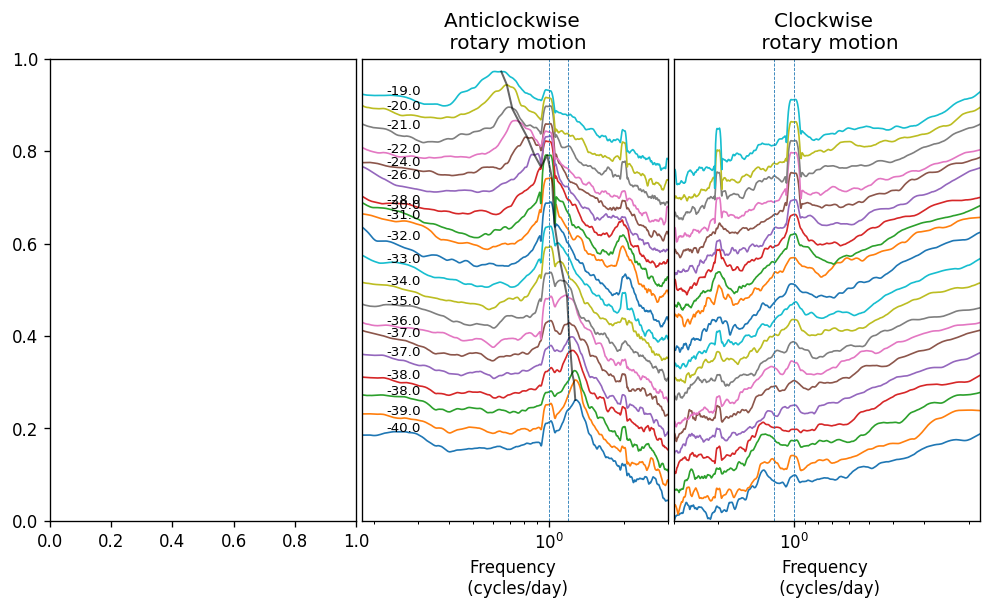

In [ ]:
pyplot.rcParams['figure.dpi'] = 120
plt.figure(figsize=(10,5))
for i in range(20,40):
  plt.subplot(1,3,2)
  plt.loglog(freq_in[i][freq_in[i]>0],savgol_filter(dens_in[i][freq_in[i]>0],20,2), linewidth = 1)#plot positive side
  plt.text(freq_in[i][freq_in[i]>0][80],dens_in[i][freq_in[i]>0][80],np.round(latz[39-i]), fontsize = 8, color = 'k')
  plt.xlim([0.18,3])
  plt.subplot(1,3,3)
  plt.loglog(-freq_in[i][freq_in[i]<0],savgol_filter(dens_in[i][freq_in[i]<0],20,2), linewidth = 1)#plot negative side
  plt.xlim([0.18,3])

plt.subplot(1,3,1)
plt.subplot(1,3,2)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency \n (cycles/day)')
plt.title('Anticlockwise \n rotary motion')
plt.plot(nearest_f[20:40].flatten(),nearest_dens[20:40].flatten(), linewidth = 1.2, color = 'k', alpha = 0.6)
plt.ylim([10e6,10e21])
plt.yticks([])
plt.subplot(1,3,3)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.gca().invert_xaxis()
plt.xlabel('Frequency \n (cycles/day)')
plt.title('Clockwise \n rotary motion')
plt.yticks([])
plt.ylim([10e6,10e21])

plt.subplots_adjust(wspace=0.02, hspace=0)

In [ ]:
import pickle

# pick exactly what you want to persist
bundle = {
    "freq_in": freq_in,
    "latz": latz,
    "nearest_f": nearest_f,
    "nearest_dens": nearest_dens,
}

with open("figure_map.pkl", "wb") as f:
    pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

In [ ]:
pwd

'/content/drive/MyDrive/dropbox_server/research_database/remote/mercator/chile/2024'

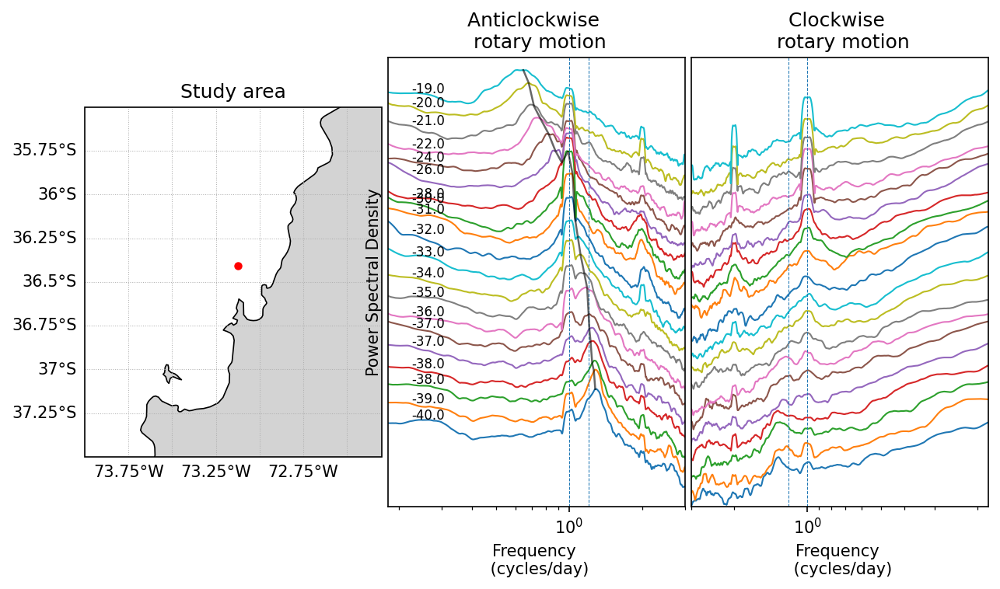

In [ ]:
lat_min, lat_max = -37.5, -35.5
lon_min, lon_max = -74.0, -72.3

plt.rcParams['figure.dpi'] = 150
fig = plt.figure(figsize=(10, 5))
gs = fig.add_gridspec(1, 3, wspace=0.02, hspace=0.0)

# --- (1) Cartopy map only on the first subplot
ax0 = fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree())
ax0.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax0.coastlines(resolution="10m", linewidth=0.8)
ax0.add_feature(cfeature.BORDERS, linewidth=0.4)
ax0.add_feature(cfeature.LAND.with_scale("10m"), facecolor="lightgray", edgecolor="none")
gl = ax0.gridlines(draw_labels=True, linestyle=":", linewidth=0.5)
gl.top_labels = False
gl.right_labels = False
plt.plot(-73.1224,-36.4075, marker='o', linestyle='none', color= 'red', markersize=4);
ax0.set_title("Study area")

# --- (2) Regular Matplotlib axes for your spectra
ax1 = fig.add_subplot(gs[0, 1])  # Anticlockwise
ax2 = fig.add_subplot(gs[0, 2])  # Clockwise

# Your looped plotting, now targeting ax1/ax2 (no effect on ax0/cartopy)
for i in range(20, 40):
    # positive (anticlockwise) side on ax1
    pos = freq_in[i] > 0
    xi = freq_in[i][pos]
    yi = dens_in[i][pos]
    ax1.loglog(xi, savgol_filter(yi, 20, 2), linewidth=1)

    # safe index near 80 to place label
    if xi.size:
        j = min(80, xi.size - 1)
        ax1.text(xi[j], yi[j], f"{np.round(latz[39 - i])}", fontsize=8, color="k")

    ax1.set_xlim([0.18, 3])

    # negative (clockwise) side on ax2
    neg = freq_in[i] < 0
    xn = -freq_in[i][neg]
    yn = dens_in[i][neg]
    ax2.loglog(xn, savgol_filter(yn, 20, 2), linewidth=1)
    ax2.set_xlim([0.18, 3])

# --- Decorations for ax1 (anticlockwise)
ax1.axvline(24/24, linestyle='--', linewidth=0.5)
ax1.axvline(24/20, linestyle='--', linewidth=0.5)
ax1.set_ylabel('Power Spectral Density')
ax1.set_xlabel('Frequency \n (cycles/day)')
ax1.set_title('Anticlockwise \n rotary motion')
ax1.plot(nearest_f[20:40].flatten(), nearest_dens[20:40].flatten(),
         linewidth=1.2, color='k', alpha=0.6)
ax1.set_ylim([1e7, 1e22])     # same as your 10e6..10e21 intent
ax1.set_yticks([])

# --- Decorations for ax2 (clockwise)
ax2.axvline(24/24, linestyle='--', linewidth=0.5)
ax2.axvline(24/20, linestyle='--', linewidth=0.5)
ax2.invert_xaxis()
ax2.set_xlabel('Frequency \n (cycles/day)')
ax2.set_title('Clockwise \n rotary motion')
ax2.set_yticks([])
ax2.set_ylim([1e7, 1e22])

fig.subplots_adjust(wspace=0.02, hspace=0.0)
plt.show()


In [ ]:
import pickle

with open("vars.pkl", "rb") as f:
    loaded = pickle.load(f)

# bring them into your workspace
globals().update(loaded)

# optional: see what you got back
list(loaded.keys())

In [ ]:
nearest_f[0:10]

array([[1.67197232],
       [1.64982699],
       [1.63875433],
       [1.62214533],
       [1.59723183],
       [1.58062284],
       [1.55017301],
       [1.52525952],
       [1.50034602],
       [1.47266436]])

In [ ]:
# SUMMER

In [ ]:
l1 = ds.sel(latitude=latz[1], longitude=lonz[1], method='nearest')

In [ ]:
l1

<xarray.Dataset> Size: 139kB
Dimensions:    (time: 8670, depth: 1)
Coordinates:
  * time       (time) datetime64[ns] 69kB 2024-01-01T23:00:00 ... 2024-12-31T...
  * depth      (depth) float32 4B 0.494
    latitude   float32 4B -19.92
    longitude  float32 4B -70.83
Data variables:
    uo         (time, depth) float32 35kB dask.array<chunksize=(1405, 1), meta=np.ndarray>
    vo         (time, depth) float32 35kB dask.array<chunksize=(1405, 1), meta=np.ndarray>
Attributes:
    Conventions:       CF-1.11
    title:             hourly mean fields from Global Ocean Physics Analysis ...
    institution:       Mercator Ocean International
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MOI GLO12
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           https://marine.copernicus.eu/contact
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_ANALYSISFORECAST_PHY_001_024
    subset:datasetId:  cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_202406
    subset:date:       2025-09-27T13:27:31.273Z

In [ ]:
dens_in = []
freq_in = []


In [ ]:
for i in range(0,len(lonz)):
  l1 = ds.sel(latitude=latz[39-i], longitude=lonz[39-i], method='nearest')
  l1 = l1.sel(time=slice("2024-01-01", "2024-02-28"))
  dt = (1)/24
  cv = l1['uo'].values.flatten()*(2**i) +1j*l1['vo'].values.flatten()*(2**i)
  P = 4
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  dens_in.append(S)
  freq_in.append(f)
  del cv, P, spec, S, f, dt

In [ ]:
nearest_value = np.full((len(lonz), 1), np.nan)
nearest_f = np.full((len(lonz), 1), np.nan)
nearest_dens = np.full((len(lonz), 1), np.nan)

for i in range(0,len(lonz)):
  z = freq_in[i][freq_in[i]>0]
  z1 = dens_in[i][freq_in[i]>0]
  vector = np.array(z)
  idx = (np.abs(vector - 24/np.abs(inertial_freq[39-i]))).argmin()
  nearest_value[i] = idx
  nearest_f[i] = z[idx]
  nearest_dens[i] = z1[idx]
  del z, vector, idx

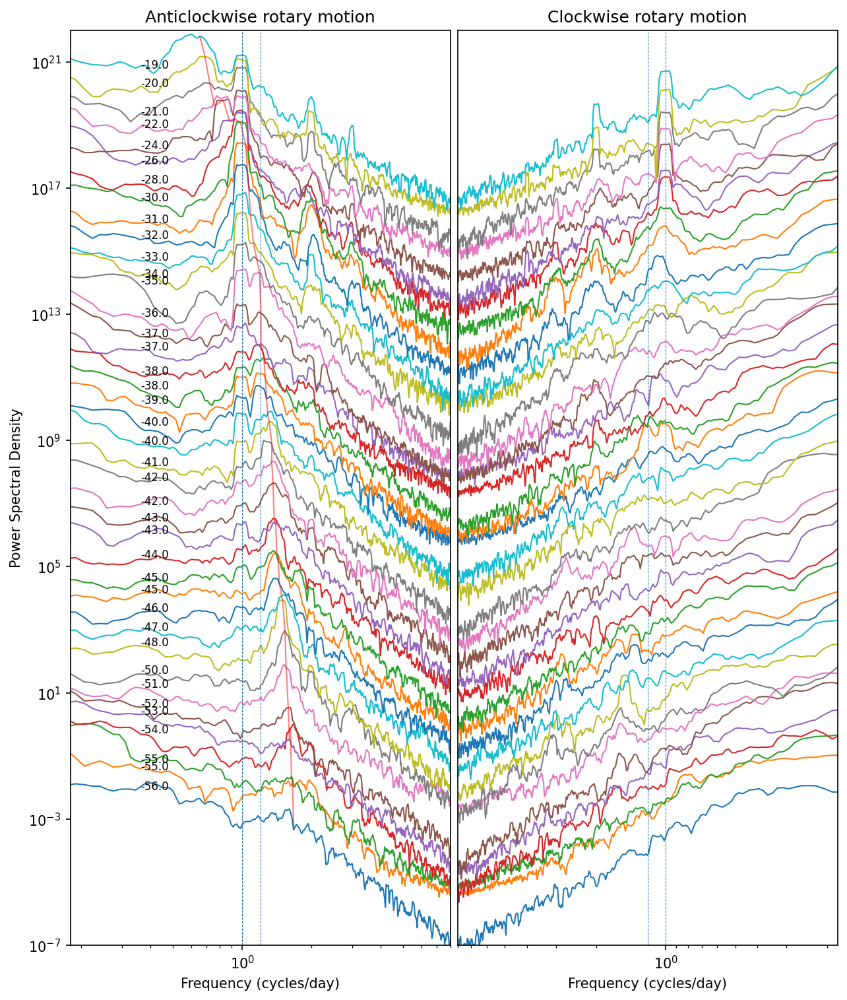

In [ ]:
pyplot.rcParams['figure.dpi'] = 150
plt.figure(figsize=(10,12))
for i in range(0,len(lonz)):
  plt.subplot(1,2,1)
  plt.loglog(freq_in[i][freq_in[i]>0],savgol_filter(dens_in[i][freq_in[i]>0],4,2), linewidth = 1)#plot positive side
  plt.text(freq_in[i][freq_in[i]>0][20],dens_in[i][freq_in[i]>0][20],np.round(latz[39-i]), fontsize = 8, color = 'k')
  plt.xlim([0.18,8])
  plt.subplot(1,2,2)
  plt.loglog(-freq_in[i][freq_in[i]<0],savgol_filter(dens_in[i][freq_in[i]<0],4,2), linewidth = 1)#plot negative side
  plt.xlim([0.18,8])

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.plot(nearest_f.flatten(),nearest_dens.flatten(), linewidth = 1, color = 'r', alpha = 0.5)
plt.ylim([10e-8,10e21])
plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.gca().invert_xaxis()
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.yticks([])
plt.ylim([10e-8,10e21])

plt.subplots_adjust(wspace=0.02, hspace=0)

In [ ]:
#winter

In [ ]:
dens_in = []
freq_in = []


In [ ]:
for i in range(0,len(lonz)):
  l1 = ds.sel(latitude=latz[39-i], longitude=lonz[39-i], method='nearest')
  l1 = l1.sel(time=slice("2024-07-01", "2024-08-30"))
  dt = (1)/24
  cv = l1['uo'].values.flatten()*(2**i) +1j*l1['vo'].values.flatten()*(2**i)
  P = 4
  spec = MTSpec(cv-np.mean(cv), nw=P, dt=dt, iadapt=1, nfft=len(cv))
  S = np.ravel(spec.spec)
  f = np.ravel(spec.freq)
  dens_in.append(S)
  freq_in.append(f)
  del cv, P, spec, S, f, dt

In [ ]:
nearest_value = np.full((len(lonz), 1), np.nan)
nearest_f = np.full((len(lonz), 1), np.nan)
nearest_dens = np.full((len(lonz), 1), np.nan)

for i in range(0,len(lonz)):
  z = freq_in[i][freq_in[i]>0]
  z1 = dens_in[i][freq_in[i]>0]
  vector = np.array(z)
  idx = (np.abs(vector - 24/np.abs(inertial_freq[39-i]))).argmin()
  nearest_value[i] = idx
  nearest_f[i] = z[idx]
  nearest_dens[i] = z1[idx]
  del z, vector, idx

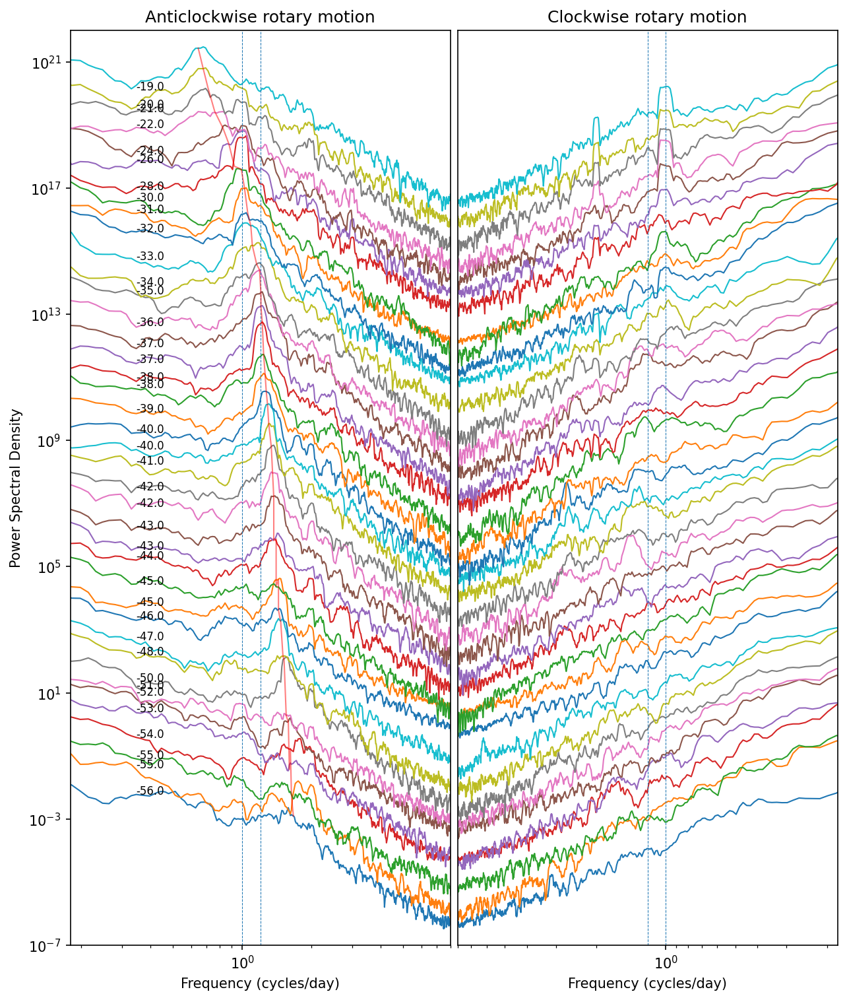

In [ ]:
pyplot.rcParams['figure.dpi'] = 150
plt.figure(figsize=(10,12))
for i in range(0,len(lonz)):
  plt.subplot(1,2,1)
  plt.loglog(freq_in[i][freq_in[i]>0],savgol_filter(dens_in[i][freq_in[i]>0],4,2), linewidth = 1)#plot positive side
  plt.text(freq_in[i][freq_in[i]>0][20],dens_in[i][freq_in[i]>0][20],np.round(latz[39-i]), fontsize = 8, color = 'k')
  plt.xlim([0.18,8])
  plt.subplot(1,2,2)
  plt.loglog(-freq_in[i][freq_in[i]<0],savgol_filter(dens_in[i][freq_in[i]<0],4,2), linewidth = 1)#plot negative side
  plt.xlim([0.18,8])

plt.subplot(1,2,1)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.ylabel('Power Spectral Density')
plt.xlabel('Frequency (cycles/day)')
plt.title('Anticlockwise rotary motion')
plt.plot(nearest_f.flatten(),nearest_dens.flatten(), linewidth = 1, color = 'r', alpha = 0.5)
plt.ylim([10e-8,10e21])
plt.subplot(1,2,2)
plt.axvline(24/24, linestyle = '--', linewidth = 0.5)
plt.axvline(24/20, linestyle = '--', linewidth = 0.5)
plt.gca().invert_xaxis()
plt.xlabel('Frequency (cycles/day)')
plt.title('Clockwise rotary motion')
plt.yticks([])
plt.ylim([10e-8,10e21])

plt.subplots_adjust(wspace=0.02, hspace=0)